# 01 · Carga, análisis exploratorio y preprocesamiento

**Proyecto:** Predicción temprana de acreditación en el Programa de Terminalidad de Educación Profesional Secundaria (TEPS) – Tierra del Fuego
**Autora:** Gabriela Soledad Bacchiani

Esta notebook corresponde a la **Entrega 2**. Contiene la carga del dataset, el análisis exploratorio (EDA) y el preprocesamiento previo al modelado. **No incluye creación ni entrenamiento de modelos.**

- La descripción del dataset, su origen y el diccionario de variables están en [`docs/dataset.md`](../docs/dataset.md).
- El dataset se genera con el script [`teps/dataset.py`](../teps/dataset.py), que unifica las planillas originales de asistencia, nómina y calificaciones (2025-2026).

**Privacidad.** Los datos reales tienen información de personas y no se publican. El archivo `data/processed/dataset_real.csv` existe (solo en mi computadora), desde esa computadora la notebook lo usa; si no, usa `dataset_sintetico.csv`, que tiene la misma estructura pero ninguna fila corresponde a una persona real. Los resultados mostrados en este repositorio corresponden a los datos reales y se presentan solo en forma agregada.

## 1. Librerías y carga del dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 40)

# Carpeta del proyecto (la notebook está dentro de notebooks/)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data" / "processed"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

# Se usan los datos reales si están disponibles; si no, los sintéticos
archivo = DATOS / "dataset_real.csv"
if not archivo.exists():
    archivo = DATOS / "dataset_sintetico.csv"
df = pd.read_csv(archivo)
print("Archivo utilizado:", archivo.name)
print("Filas (registros estudiante-nivel):", df.shape[0], "| Columnas:", df.shape[1])

Archivo utilizado: dataset_real.csv
Filas (registros estudiante-nivel): 153 | Columnas: 28


## 2. Estructura general

Cada fila es un **registro estudiante-nivel**: una persona que cursó un nivel en un cuatrimestre. Una misma persona puede aparecer varias veces si cursó más de un nivel. Revisamos los tipos de datos de cada columna.

In [2]:
# Tipo de dato y cantidad de valores no nulos de cada variable
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_estudiante             153 non-null    str    
 1   anio                      153 non-null    int64  
 2   cuatri                    153 non-null    int64  
 3   nivel                     153 non-null    int64  
 4   grupo                     153 non-null    str    
 5   rango_edad                149 non-null    str    
 6   sexo                      149 non-null    str    
 7   empresa_grupo             153 non-null    str    
 8   sector                    153 non-null    str    
 9   turno_laboral             153 non-null    str    
 10  lugar_trabajo             153 non-null    str    
 11  convenio_uom              153 non-null    int64  
 12  clases_dictadas_corte     153 non-null    int64  
 13  pct_asistencia            149 non-null    float64
 14  pct_asist_electronica

In [3]:
# Cuántas personas distintas hay y cuántos registros tiene cada una
print("Estudiantes únicos:", df.id_estudiante.nunique())
print(df.groupby("id_estudiante").size().value_counts().sort_index()
        .rename("cantidad de estudiantes").rename_axis("niveles cursados"))

Estudiantes únicos: 83
niveles cursados
1    39
2    28
3     6
4    10
Name: cantidad de estudiantes, dtype: int64


## 3. Población del modelo

No todos los registros sirven para entrenar el modelo. La columna `motivo_exclusion` (generada por el script) indica por qué se deja afuera un registro:

- **en curso**: nivel 4 del 2° cuatrimestre de 2026; todavía no tienen resultado. Se usarán para aplicar el modelo, no para entrenarlo ni evaluarlo.
- **no inició**: sin ninguna asistencia hasta el 1° cierre parcial. El no inicio se analiza de forma descriptiva; el modelo predice a mitad del cuatrimestre y no puede anticiparlo.
- **baja avisada antes del corte**: ya no hay nada que anticipar.
- **situación no estándar**: un caso de reasignación de nivel por equivalencias durante el cuatrimestre.

In [4]:
# Tabla de frecuencias de los motivos de exclusión
motivos = df.motivo_exclusion.fillna("incluido en el modelo").value_counts()
display(motivos.to_frame("registros").assign(porcentaje=lambda t: (100 * t.registros / len(df)).round(1)))

,registros,porcentaje
motivo_exclusion,,
incluido en el modelo,121,79.1
en curso (sin resultado todavía),19,12.4
no inició (sin asistencia hasta el corte),12,7.8
situación no estándar (revisar a mano),1,0.7


In [5]:
# Nos quedamos solo con los registros que forman parte del modelo
modelo = df[df.motivo_exclusion.isna()].copy()
print("Registros para el modelo:", len(modelo), "| Estudiantes únicos:", modelo.id_estudiante.nunique())

Registros para el modelo: 121 | Estudiantes únicos: 75


## 4. Variable objetivo: `acredita`

`acredita = 1` si el estudiante aprobó las 6 materias del nivel al cierre final del cuatrimestre (en la planilla figura como *PROMUEVE* o *EGRESADO*); `acredita = 0` si no (figura con el nivel que adeuda). Primero vemos si las clases están balanceadas.

In [6]:
# Tabla de frecuencias de la variable objetivo
objetivo = modelo.acredita.map({1: "Acredita", 0: "No acredita"}).value_counts()
display(objetivo.to_frame("registros").assign(porcentaje=lambda t: (100 * t.registros / t.registros.sum()).round(1)))

,registros,porcentaje
acredita,,
Acredita,74,61.2
No acredita,47,38.8


,registros,acreditan,tasa_acreditacion_%
periodo,,,
2025-1C N1,23,15.0,65.2
2025-1C N3,34,19.0,55.9
2025-2C N2,18,11.0,61.1
2025-2C N4,24,11.0,45.8
2026-1C N3,22,18.0,81.8


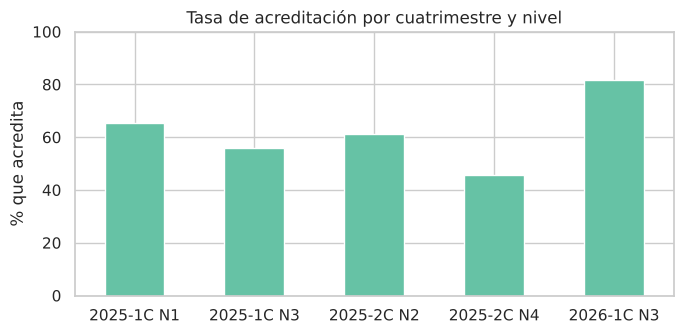

In [7]:
# Acreditación por cuatrimestre y nivel: cantidad de registros y tasa de acreditación
modelo["periodo"] = modelo.anio.astype(str) + "-" + modelo.cuatri.astype(str) + "C N" + modelo.nivel.astype(str)
por_periodo = modelo.groupby("periodo").acredita.agg(registros="count", acreditan="sum")
por_periodo["tasa_acreditacion_%"] = (100 * por_periodo.acreditan / por_periodo.registros).round(1)
display(por_periodo)

ax = por_periodo["tasa_acreditacion_%"].plot(kind="bar", color="#66c2a5", figsize=(7, 3.5), rot=0)
ax.set_ylabel("% que acredita"); ax.set_xlabel(""); ax.set_ylim(0, 100)
ax.set_title("Tasa de acreditación por cuatrimestre y nivel")
plt.tight_layout(); plt.savefig(FIGURAS / "acreditacion_por_periodo.png", dpi=120); plt.show()

## 5. Valores faltantes

Antes de transformar, revisamos cuántos datos faltan en cada variable y por qué.

In [8]:
faltantes = modelo.drop(columns=["motivo_exclusion"]).isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)
display(faltantes.to_frame("faltantes").assign(porcentaje=lambda t: (100 * t.faltantes / len(modelo)).round(1)))

,faltantes,porcentaje
promedio_1p,17,14.0
promedio_tps,14,11.6
pct_asist_electronica,5,4.1
rango_edad,3,2.5
sexo,3,2.5
pct_asist_general,1,0.8
pct_tps_entregados,1,0.8
materias_1p_menor6,1,0.8


Los faltantes no son errores de carga al azar; la mayoría tiene una explicación:

- `promedio_tps`: falta cuando el estudiante **no entregó ningún TP** hasta el corte (no hay notas para promediar).
- `promedio_1p`: falta cuando **no tiene ninguna 1° nota parcial**. Según la devolución de la Entrega 1, estos estudiantes **no se excluyen**, porque son justamente los que necesitan acompañamiento.
- `pct_asist_electronica` / `pct_asist_general`: falta cuando hasta el corte no hubo clases de ese campo para ese estudiante.
- `sexo` y `rango_edad`: faltan en la nómina de algunos estudiantes.

El tratamiento de cada caso se define en la sección 9.

## 6. Variables numéricas

Medidas resumen de las variables numéricas, todas calculadas con la información disponible **hasta el 1° cierre parcial**.

In [9]:
numericas = ["clases_dictadas_corte", "pct_asistencia", "pct_asist_electronica", "pct_asist_general",
             "pct_ausente_sin_aviso", "pct_ausente_con_aviso", "licencias_medicas",
             "presente_turno_contrario", "pct_tps_entregados", "promedio_tps", "promedio_1p",
             "materias_1p_menor6", "materias_sin_1p"]
display(modelo[numericas].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
clases_dictadas_corte,121.0,9.86,3.00,4.00,8.00,9.00,11.00,16.00
pct_asistencia,121.0,0.66,0.26,0.06,0.44,0.75,0.89,1.00
pct_asist_electronica,116.0,0.71,0.28,0.00,0.50,0.76,1.00,1.00
pct_asist_general,120.0,0.71,0.30,0.00,0.50,0.75,1.00,1.00
pct_ausente_sin_aviso,121.0,0.28,0.25,0.00,0.00,0.25,0.46,0.85
pct_ausente_con_aviso,121.0,0.06,0.09,0.00,0.00,0.00,0.11,0.38
licencias_medicas,121.0,0.09,0.53,0.00,0.00,0.00,0.00,4.00
presente_turno_contrario,121.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
pct_tps_entregados,120.0,0.70,0.37,0.00,0.40,0.91,1.00,1.00
promedio_tps,107.0,7.98,1.05,2.00,7.61,8.12,8.67,10.00


In [10]:
# Comparamos las medias de cada variable entre quienes acreditan y quienes no
display(modelo.groupby("acredita")[numericas].mean().T.round(2)
        .rename(columns={0: "No acredita", 1: "Acredita"}))

acredita,No acredita,Acredita
clases_dictadas_corte,10.04,9.74
pct_asistencia,0.48,0.78
pct_asist_electronica,0.54,0.82
pct_asist_general,0.51,0.84
pct_ausente_sin_aviso,0.45,0.17
pct_ausente_con_aviso,0.07,0.05
licencias_medicas,0.06,0.11
presente_turno_contrario,0.00,0.00
pct_tps_entregados,0.37,0.91
promedio_tps,7.53,8.18


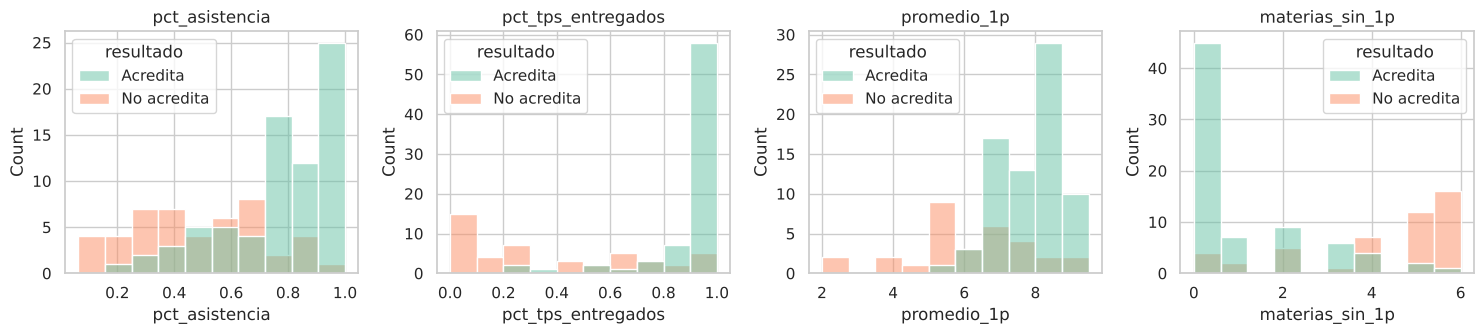

In [11]:
# Histogramas de las variables tempranas principales, separados por resultado.
# Sirven para ver si las distribuciones de los dos grupos se superponen o se separan.
principales = ["pct_asistencia", "pct_tps_entregados", "promedio_1p", "materias_sin_1p"]
etiquetas = modelo.acredita.map({1: "Acredita", 0: "No acredita"})
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, var in zip(ejes, principales):
    sns.histplot(data=modelo.assign(resultado=etiquetas), x=var, hue="resultado", bins=10,
                 multiple="layer", ax=ax, stat="count", common_norm=False)
    ax.set_title(var)
plt.tight_layout(); plt.savefig(FIGURAS / "histogramas_por_resultado.png", dpi=120); plt.show()

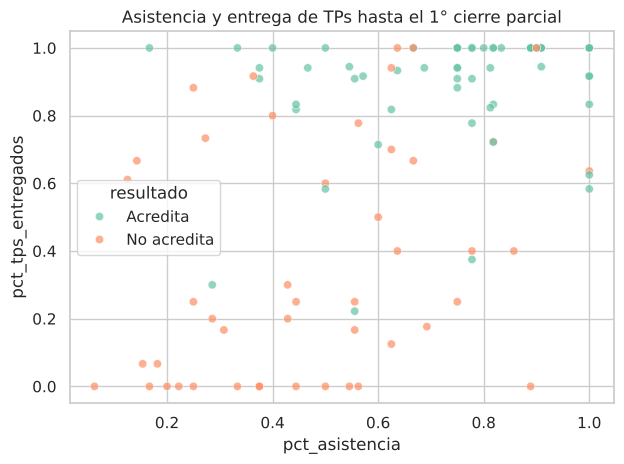

In [12]:
# Diagrama de dispersión: asistencia vs. TPs entregados hasta el corte, coloreado por resultado
ax = sns.scatterplot(data=modelo.assign(resultado=etiquetas), x="pct_asistencia", y="pct_tps_entregados",
                     hue="resultado", alpha=0.7)
ax.set_title("Asistencia y entrega de TPs hasta el 1° cierre parcial")
plt.tight_layout(); plt.savefig(FIGURAS / "dispersion_asistencia_tps.png", dpi=120); plt.show()

## 7. Variables categóricas

Tablas de frecuencia de cada variable categórica y tasa de acreditación en cada categoría. Algunas categorías tienen pocos casos: en esas, el porcentaje es poco estable y no conviene sacar conclusiones fuertes.

In [13]:
categoricas = ["cuatri", "nivel", "grupo", "rango_edad", "sexo", "empresa_grupo", "sector",
               "turno_laboral", "lugar_trabajo", "convenio_uom"]
for var in categoricas:
    t = modelo.groupby(modelo[var].fillna("Sin dato")).acredita.agg(registros="count", acreditan="sum")
    t["tasa_acreditacion_%"] = (100 * t.acreditan / t.registros).round(1)
    print(f"\n=== {var} ===")
    display(t)


=== cuatri ===


,registros,acreditan,tasa_acreditacion_%
cuatri,,,
1,79,52.0,65.8
2,42,22.0,52.4



=== nivel ===


,registros,acreditan,tasa_acreditacion_%
nivel,,,
1,23,15.0,65.2
2,18,11.0,61.1
3,56,37.0,66.1
4,24,11.0,45.8



=== grupo ===


,registros,acreditan,tasa_acreditacion_%
grupo,,,
12:30,37,23.0,62.2
15:30,84,51.0,60.7


... (10 outputs left out)


=== lugar_trabajo ===


,registros,acreditan,tasa_acreditacion_%
lugar_trabajo,,,
Misma planta que el cursado,10,3.0,30.0
Otra planta,43,25.0,58.1
Rotativo,28,25.0,89.3
Sin dato,40,21.0,52.5



=== convenio_uom ===


,registros,acreditan,tasa_acreditacion_%
convenio_uom,,,
0,67,46.0,68.7
1,54,28.0,51.9


## 8. Relación entre variables numéricas

La matriz de correlación permite detectar variables que miden casi lo mismo (redundancia).

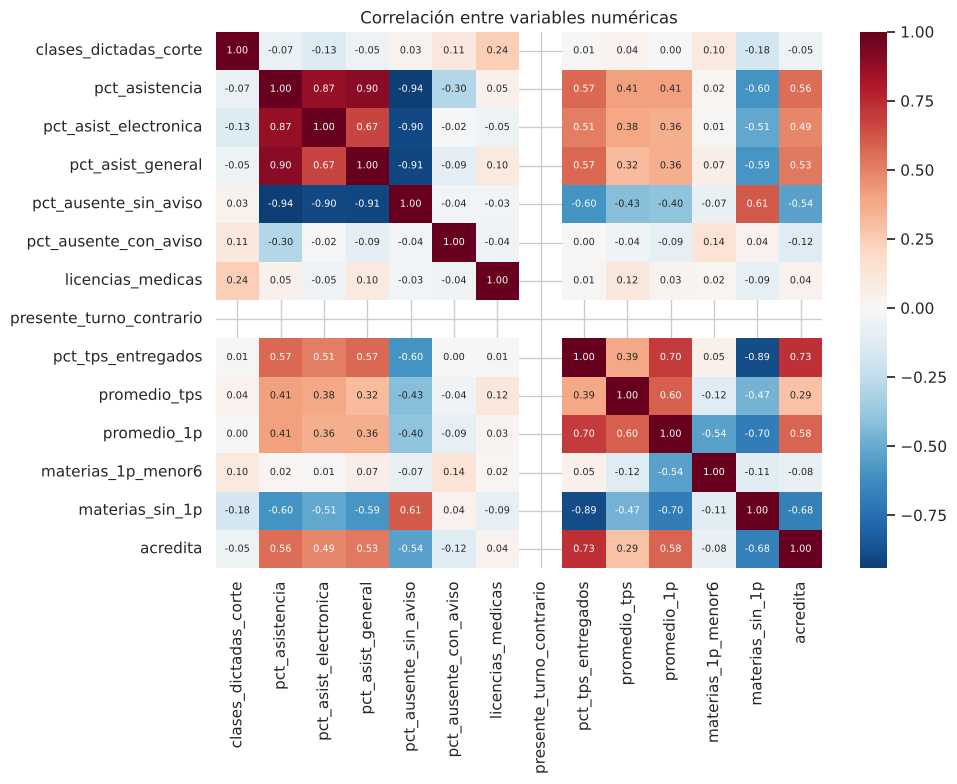

In [14]:
corr = modelo[numericas + ["acredita"]].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlación entre variables numéricas")
plt.tight_layout(); plt.savefig(FIGURAS / "correlaciones.png", dpi=120); plt.show()

## 9. Preprocesamiento

### 9.1 Selección de variables

Se eliminan columnas que no deben entrar al modelo:

- `id_estudiante`: es un identificador, no una característica. Se conserva aparte para separar los datos por estudiante.
- `situacion`: es el resultado escrito en la planilla; usarla sería **fuga de datos** (el modelo vería la respuesta).
- `motivo_exclusion`, `periodo`, `anio`: son de control. El año no se usa como predictor porque el modelo se aplicará a años futuros.
- `pct_ausente_sin_aviso`: tiene una correlación de −0,94 con `pct_asistencia` (sección 8); mide prácticamente lo mismo, así que es redundante.
- `presente_turno_contrario`: vale 0 en todos los registros de 2025-2026 (el código de asistencia al turno contrario no se usó en esos años), por lo que no aporta información.

In [15]:
objetivo_col = "acredita"
grupos = modelo["id_estudiante"]          # para separar por estudiante
eliminar = ["id_estudiante", "situacion", "motivo_exclusion", "periodo", "anio",
            "pct_ausente_sin_aviso", "presente_turno_contrario"]
X = modelo.drop(columns=eliminar + [objetivo_col])
y = modelo[objetivo_col].astype(int)

num_vars = ["clases_dictadas_corte", "pct_asistencia", "pct_asist_electronica", "pct_asist_general",
            "pct_ausente_con_aviso", "licencias_medicas",
            "pct_tps_entregados", "promedio_tps", "promedio_1p", "materias_1p_menor6", "materias_sin_1p"]
cat_vars = ["cuatri", "nivel", "grupo", "rango_edad", "sexo", "empresa_grupo", "sector",
            "turno_laboral", "lugar_trabajo", "convenio_uom"]
print("Variables numéricas:", len(num_vars), "| Variables categóricas:", len(cat_vars))

Variables numéricas: 11 | Variables categóricas: 10


### 9.2 Separación en entrenamiento y prueba

Siguiendo la devolución de la Entrega 1, la separación cumple **dos criterios a la vez**:

1. **Orden de las cohortes:** se entrena con 2025 y se prueba con el 1° cuatrimestre de 2026, que es lo más parecido al uso real (aprender del pasado para predecir lo nuevo).
2. **Ninguna persona en los dos conjuntos:** quienes están en la prueba de 2026 y ya habían cursado en 2025 se quitan del entrenamiento.

La separación se hace **antes** de imputar y escalar, para que esas transformaciones se calculen solo con los datos de entrenamiento y no se filtre información de la prueba.

In [16]:
es_prueba = (modelo.anio == 2026) & (modelo.cuatri == 1)
ids_prueba = set(grupos[es_prueba])
es_entrenamiento = (modelo.anio == 2025) & ~grupos.isin(ids_prueba)

X_train, y_train = X[es_entrenamiento], y[es_entrenamiento]
X_test, y_test = X[es_prueba], y[es_prueba]
print(f"Registros 2025 quitados del entrenamiento por repetir persona: {((modelo.anio == 2025) & grupos.isin(ids_prueba)).sum()}")
print(f"Entrenamiento: {len(X_train)} registros | Prueba: {len(X_test)} registros")
print("Proporción que acredita -> entrenamiento:", round(y_train.mean(), 2), "| prueba:", round(y_test.mean(), 2))

Registros 2025 quitados del entrenamiento por repetir persona: 24
Entrenamiento: 75 registros | Prueba: 22 registros
Proporción que acredita -> entrenamiento: 0.48 | prueba: 0.82


### 9.3 Imputación, codificación y escalado

| Paso | Variables | Decisión y justificación |
|---|---|---|
| Imputación | `promedio_tps` | Si no entregó ningún TP, el promedio se completa con **0**: la ausencia de entregas es información, no un dato perdido. |
| Imputación | resto de las numéricas | **Mediana del conjunto de entrenamiento**, porque es menos sensible a valores extremos que la media. |
| Imputación | categóricas | Categoría **"Sin dato"**, para no perder esos registros. |
| Codificación | categóricas | **One-hot encoding**: cada categoría pasa a ser una columna 0/1, porque los modelos de scikit-learn necesitan números y estas categorías no tienen un orden. |
| Escalado | numéricas | **StandardScaler** (media 0, desvío 1). Las variables están en escalas distintas (proporciones de 0 a 1, notas de 1 a 10, cantidades), y la regresión logística con regularización y los métodos basados en distancias (como KNN) son sensibles a esa diferencia. El escalado **no** elimina la correlación ni la redundancia entre variables; solo lleva todo a una escala común. El árbol de decisión no lo necesita, pero no lo perjudica. |

In [17]:
X_train = X_train.copy(); X_test = X_test.copy()
for parte in (X_train, X_test):
    parte["promedio_tps"] = parte["promedio_tps"].fillna(0)        # sin TPs entregados -> 0
    parte[cat_vars] = parte[cat_vars].astype(str).replace("nan", "Sin dato")

preprocesador = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), num_vars),
    ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="Sin dato")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_vars),
])

# fit solo con entrenamiento; transform en los dos conjuntos
X_train_p = preprocesador.fit_transform(X_train)
X_test_p = preprocesador.transform(X_test)
columnas_finales = preprocesador.get_feature_names_out()
print("Columnas después del preprocesamiento:", len(columnas_finales))

Columnas después del preprocesamiento: 44


In [18]:
# Verificación: después del escalado, las numéricas de entrenamiento tienen media ~0 y desvío ~1
control = pd.DataFrame(X_train_p[:, :len(num_vars)], columns=num_vars)
display(control.agg(["mean", "std"]).T.round(2))

,mean,std
clases_dictadas_corte,0.0,1.01
pct_asistencia,-0.0,1.01
pct_asist_electronica,-0.0,1.01
pct_asist_general,0.0,1.01
pct_ausente_con_aviso,0.0,1.01
licencias_medicas,0.0,1.01
pct_tps_entregados,0.0,1.01
promedio_tps,0.0,1.01
promedio_1p,0.0,1.01
materias_1p_menor6,-0.0,1.01


### 9.4 Guardado de los datos preprocesados

Se guardan los conjuntos listos para la etapa de modelado (Entrega 3). Si se trabajó con los datos reales, estos archivos quedan solo en mi computadora (`.gitignore` impide subirlos).

In [19]:
sufijo = "real" if archivo.name == "dataset_real.csv" else "sintetico"
pd.DataFrame(X_train_p, columns=columnas_finales).assign(acredita=y_train.values, id_estudiante=grupos[es_entrenamiento].values) \
    .to_csv(DATOS / f"train_preprocesado_{sufijo}.csv", index=False)
pd.DataFrame(X_test_p, columns=columnas_finales).assign(acredita=y_test.values, id_estudiante=grupos[es_prueba].values) \
    .to_csv(DATOS / f"test_preprocesado_{sufijo}.csv", index=False)
print("Guardados:", f"train_preprocesado_{sufijo}.csv", "y", f"test_preprocesado_{sufijo}.csv")

Guardados: train_preprocesado_real.csv y test_preprocesado_real.csv


## 10. Conclusiones del análisis exploratorio

Para realizar este trabajo se tomaron los registros de las cohortes 2025 - 2026, del Proyecto de Terminalidad de Educación Secundaria - Profesional. De lo observado, se puede concluir: 

- De 153 registros de estudiantes - nivel (83 estudiantes únicos), 121 forman la población del modelo (75 estudiantes). El 61,2 % acredita y el 38,8 % no: las clases no están muy desbalanceadas, están bastante equilibradas y se acercan a un modelo ideal de 50 % y 50 %.
- La tasa de acreditación varía entre períodos: 45,8 % en nivel 4 (2° cuatrimestre 2025) y 81,8 % en nivel 3 (1° cuatrimestre 2026).
- Las variables tempranas separan bien a los dos grupos: quienes acreditan tienen en promedio 78 % de asistencia hasta el corte (contra 48 %), entregaron el 91 % de los TPs (contra 37 %) y les faltan notas parciales en 1,0 materias (contra 4,2).
- La variable con mayor correlación con `acredita` es el porcentaje de TPs entregados (0,73), seguida por las materias sin 1° nota (−0,68).
- En las categóricas aparecen diferencias (por ejemplo, según sector o lugar de trabajo), pero varias categorías tienen menos de 30 registros, así que esas diferencias deben tomarse con precaución, solo a modo de información.
- El conjunto de prueba (2026) tiene una proporción de acreditación (82 %) mucho mayor que el de entrenamiento (48 %); esto habrá que tenerlo en cuenta al interpretar las métricas.